In [5]:
import os, gc, json, time, warnings, multiprocessing as mp
import numpy as np, pandas as pd
import pandas_ta as ta
import ccxt
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

SYMBOL = "SOL/USDT"
TIMEFRAME = "5m"
YEARS = 4
EXCHANGE_ID = "binance"
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)
RAW_PATH = f"{DATA_DIR}/raw_data.parquet"
IND_PATH = f"{DATA_DIR}/all_indicators.parquet"
FAILED_PATH = f"{DATA_DIR}/failed_indicators.json"
RUNTIME_PATH = f"{DATA_DIR}/indicator_runtime.csv"
CHECKPOINT_PATH = f"{DATA_DIR}/checkpoint.parquet"
CHECKPOINT_META = f"{DATA_DIR}/checkpoint_meta.json"

CORES = max(1, mp.cpu_count() - 1)
pd.set_option("mode.copy_on_write", True)

In [4]:
def fetch_ohlcv_all(symbol=SYMBOL, timeframe=TIMEFRAME, years=YEARS):
    ex = getattr(ccxt, EXCHANGE_ID)({"enableRateLimit": True})
    ms_per_candle = ex.parse_timeframe(timeframe) * 1000
    since = ex.milliseconds() - years * 365 * 24 * 60 * 60 * 1000
    limit = 1000
    out = []
    pbar = tqdm(desc="downloading", unit="candles")
    while True:
        batch = ex.fetch_ohlcv(symbol, timeframe, since=since, limit=limit)
        if not batch:
            break
        out.extend(batch)
        since = batch[-1][0] + ms_per_candle
        pbar.update(len(batch))
        if len(batch) < limit and since >= ex.milliseconds():
            break
        time.sleep(ex.rateLimit / 1000)
    pbar.close()
    df = pd.DataFrame(out, columns=["timestamp","open","high","low","close","volume"])
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df = df.drop_duplicates("timestamp").sort_values("timestamp").reset_index(drop=True)
    return df

if not os.path.exists(RAW_PATH):
    raw_df = fetch_ohlcv_all()
else:
    raw_df = pd.read_parquet(RAW_PATH)
print(raw_df.shape)

NameError: name 'SYMBOL' is not defined

In [6]:

raw_df = pd.read_parquet(RAW_PATH)
raw_df.to_parquet(RAW_PATH, index=False)
print(f"saved {RAW_PATH}", raw_df.shape)

saved data/raw_data.parquet (420464, 6)


In [7]:
df = pd.read_parquet(RAW_PATH)
df["timestamp"] = pd.to_datetime(df["timestamp"])
for c in ["open","high","low","close","volume"]:
    df[c] = df[c].astype("float32")
df = df.set_index("timestamp").sort_index()
open_, high, low, close, volume = df["open"], df["high"], df["low"], df["close"], df["volume"]
print(df.shape, df.dtypes.to_dict())

(420464, 5) {'open': dtype('float32'), 'high': dtype('float32'), 'low': dtype('float32'), 'close': dtype('float32'), 'volume': dtype('float32')}


In [8]:
EXCLUDE_CATEGORIES = {"candles"}
EXCLUDE_NAMES = {
    "above","above_value","below","below_value","cross","cross_value",
    "long_run","short_run","increasing","decreasing",
    "ichimoku",
}

def build_indicator_list():
    plan = []
    for cat, names in ta.Category.items():
        if cat in EXCLUDE_CATEGORIES:
            continue
        for name in names:
            if name in EXCLUDE_NAMES:
                continue
            if not hasattr(ta, name):
                continue
            plan.append((cat, name))
    return plan

INDICATOR_PLAN = build_indicator_list()
print(f"planned indicators: {len(INDICATOR_PLAN)}")

planned indicators: 146


In [10]:
def call_indicator(name):
    fn = getattr(ta, name)
    kwargs_variants = [
        dict(open=open_, high=high, low=low, close=close, volume=volume),
        dict(high=high, low=low, close=close, volume=volume),
        dict(high=high, low=low, close=close),
        dict(close=close, volume=volume),
        dict(close=close),
    ]
    last_err = None
    for kw in kwargs_variants:
        try:
            res = fn(**kw)
            if res is None:
                continue
            if isinstance(res, pd.Series):
                res = res.to_frame(name if res.name is None else res.name)
            if isinstance(res, pd.DataFrame) and len(res) == len(df):
                return res
        except TypeError as e:
            last_err = e
            continue
        except Exception as e:
            last_err = e
            break
    if last_err:
        raise last_err
    raise ValueError("no compatible signature")

def load_checkpoint():
    if os.path.exists(CHECKPOINT_PATH) and os.path.exists(CHECKPOINT_META):
        cp = pd.read_parquet(CHECKPOINT_PATH)
        meta = json.load(open(CHECKPOINT_META))
        return cp, meta
    base = pd.DataFrame(index=df.index)
    return base, {"done": [], "failed": {}, "runtime": {}}

results_df, meta = load_checkpoint()
done = set(meta["done"])
failed = meta["failed"]
runtime = meta["runtime"]

CHECKPOINT_EVERY = 15
pending = [(c, n) for c, n in INDICATOR_PLAN if n not in done and n not in failed]
new_frames = []

for i, (cat, name) in enumerate(tqdm(pending, desc="indicators")):
    t0 = time.time()
    try:
        res = call_indicator(name)
        res = res.astype("float32", errors="ignore")
        res.columns = [f"{name}_{c}" if not str(c).startswith(name) else str(c) for c in res.columns]
        new_frames.append(res)
        done.add(name)
        runtime[name] = round(time.time() - t0, 4)
    except Exception as e:
        failed[name] = str(e)
        runtime[name] = round(time.time() - t0, 4)

    if new_frames and (i + 1) % CHECKPOINT_EVERY == 0:
        results_df = pd.concat([results_df] + new_frames, axis=1, copy=False)
        new_frames = []
        results_df.to_parquet(CHECKPOINT_PATH)
        json.dump({"done": list(done), "failed": failed, "runtime": runtime}, open(CHECKPOINT_META, "w"))
        gc.collect()

if new_frames:
    results_df = pd.concat([results_df] + new_frames, axis=1, copy=False)
    new_frames = []
results_df.to_parquet(CHECKPOINT_PATH)
json.dump({"done": list(done), "failed": failed, "runtime": runtime}, open(CHECKPOINT_META, "w"))
gc.collect()
print(f"done={len(done)} failed={len(failed)}")

indicators: 0it [00:00, ?it/s]

done=132 failed=14


In [16]:
final_df = pd.concat([df, results_df], axis=1, copy=False)
final_df = final_df.loc[:, ~final_df.columns.duplicated()]
final_df.to_parquet(IND_PATH)

json.dump(failed, open(FAILED_PATH, "w"), indent=2)
pd.Series(runtime, name="seconds").sort_values(ascending=False).to_csv(RUNTIME_PATH, header=True)

total_time = sum(runtime.values())
mem_mb = final_df.memory_usage(deep=True).sum() / 1e6

print(f"attempted:  {len(INDICATOR_PLAN)}")
print(f"successful: {len(done)}")
print(f"failed:     {len(failed)}")
print(f"runtime:    {total_time:.1f}s")
print(f"shape:      {final_df.shape}")
print(f"RAM:        {mem_mb:.1f} MB")

attempted:  146
successful: 132
failed:     14
runtime:    279.1s
shape:      (420464, 230)
RAM:        390.2 MB


                                mean         std        min          max  \
wcp_WCP                   417.910492  272.207764  32.639999  1177.079956   
hlc3_HLC3                 104.477234   68.051949   8.160000   294.129974   
midpoint_MIDPOINT_2       104.478912   68.053535   8.170000   294.445007   
decay_LDECAY_1            104.487816   68.065742   8.160000   294.690002   
hl2_HL2                   104.476448   68.050804   8.160000   293.849976   
mama_MAMA_0.5_0.05        104.479065   68.053238   8.241965   292.696289   
tema_TEMA_10              104.480118   68.054131   8.174457   294.755890   
high                      104.661537   68.172340   8.250000   295.829987   
zlma_ZL_EMA_10            104.480103   68.053955   8.170373   294.482605   
low                       104.291382   67.927818   8.000000   292.739990   
midprice_MIDPRICE_2       104.475159   68.050049   8.165000   293.804993   
fwma_FWMA_10              104.480011   68.052704   8.268532   292.353424   
jma_JMA_7_0.

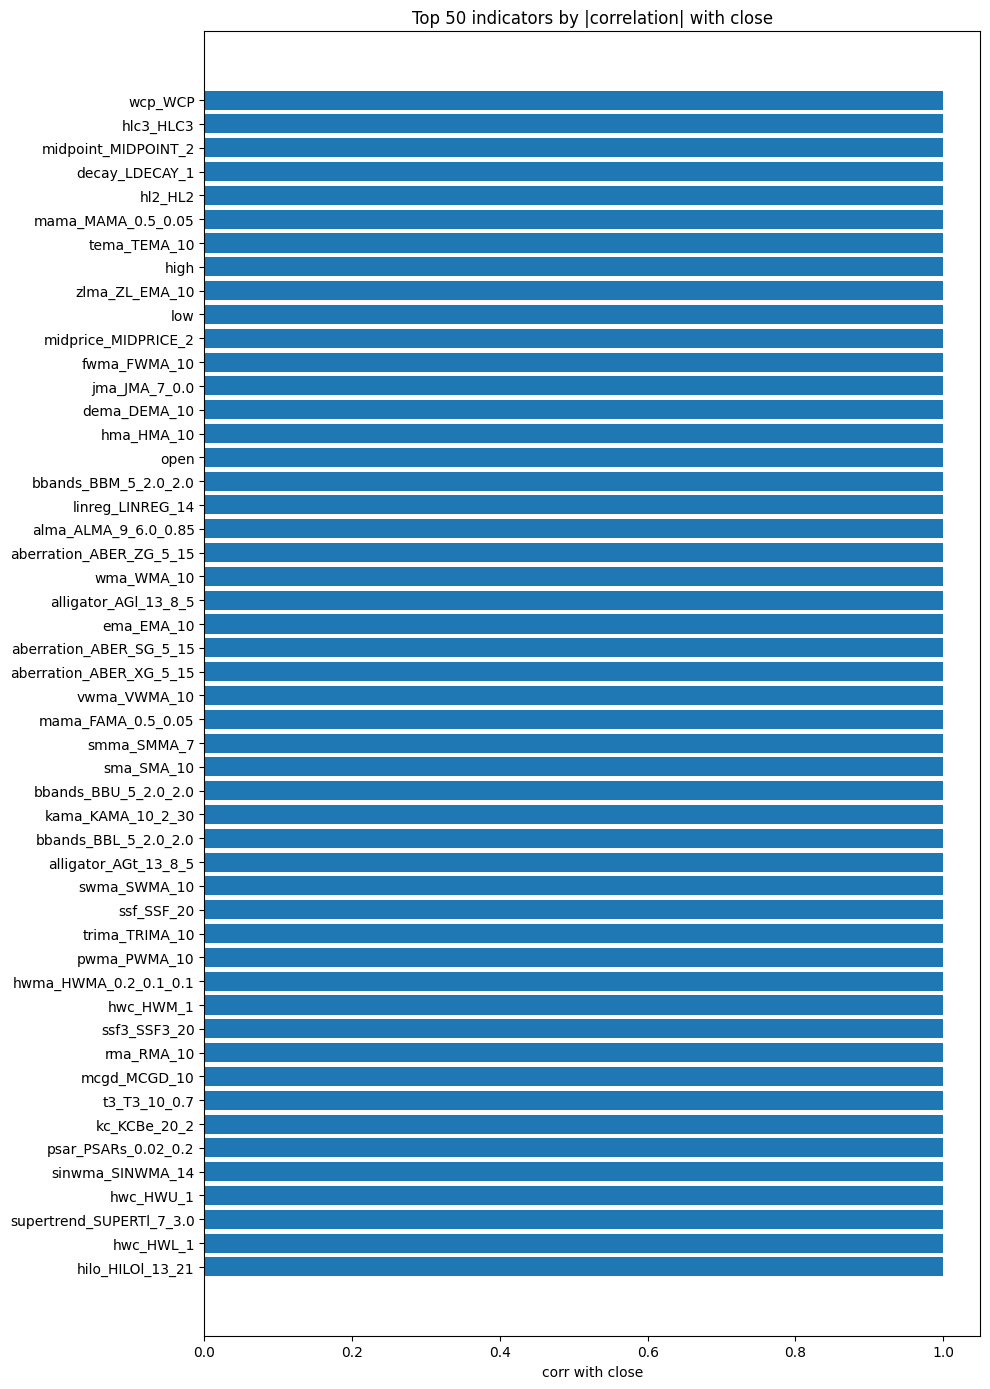

In [18]:
corr = final_df.corr(numeric_only=True)["close"].drop("close").dropna().sort_values(key=abs, ascending=False)
top50 = corr.head(50)
stats = final_df[top50.index].agg(["mean","std","min","max"]).T
stats["abs_corr_close"] = top50
stats = stats.sort_values("abs_corr_close", ascending=False)
print(stats)

import matplotlib.pyplot as plt
plt.figure(figsize=(10,14))
plt.barh(top50.index[::-1], top50.values[::-1])
plt.xlabel("corr with close")
plt.title("Top 50 indicators by |correlation| with close")
plt.tight_layout()
plt.savefig(f"{DATA_DIR}/top50_corr.png", dpi=120)
plt.show()